In [1]:
display("text/html", "<style>.container { width:100% !important; }</style>")

In [2]:
using DataFrames, CSV, Plots, LaTeXStrings, DelimitedFiles, GLM, BlackBoxOptim, Distances, Printf, Plots.Measures

In [3]:
Plots.theme(:dao)

In [4]:
include("/home/jamesh/GitHub/Ecological-Preferential-Attachment/diversity-simulator.jl")
using .dsim

In [5]:
pal = cgrad(:tol_muted);
cpal10 = [pal[i] for i in 0.0:1/46:1];

In [6]:
read_data = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Data_csv/Grilli-crosssecdata__datatax.csv", DataFrame)
# first split on classification
gd1 = groupby(read_data, :classification);

For each classification, split up on the sample.

In [7]:
gd_classes = []
for gd in gd1
    push!(gd_classes, groupby(gd, :sample_id))
end

In [8]:
read_data = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Data_csv/Grilli-crosssecdata__datatax.csv", DataFrame)
read_data = filter(:nreads => !=(0), read_data)
# first split on classification
gd1 = groupby(read_data, :classification);

gd_classes = []
for gd in gd1
    push!(gd_classes, groupby(gd, :sample_id))
end

classes = [gd_classes[i][1][!,:classification][2] for i in 1:length(gd_classes)]
classes = strip.(lowercase.(classes))
classes[10] = "marine hydrothermal vents"
classes[6] = "oral cavity"
classes[5] = "terrestrial soil"
classes[end] = "activated sludge"
classes

14-element Vector{SubString{String}}:
 "seawater"
 "oral"
 "gut"
 "vaginal"
 "terrestrial soil"
 "oral cavity"
 "feces"
 "skin"
 "glacier"
 "marine hydrothermal vents"
 "river"
 "lake"
 "environmental aquatic marine"
 "activated sludge"

In [9]:
cpal_plot =  [pal[i] for i in 0.0:1/11:1]

# Index 1

Index choice below specifies the index of system we are dealing with.

In [86]:
ind_choice = 1;

In [87]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [88]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

492477.0

In [89]:
small_to_large = sortperm(sizes);

In [90]:
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [91]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

3.479563394700048

Let's import the calibration results.

In [92]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.697582,1.1302,5.28994
2,0.544401,1.01172,5.14817
3,0.59134,1.00869,4.05522
4,1.49568,1.32765,12.8014
5,0.600075,1.05914,4.78453
6,0.571768,1.04917,5.69756
7,0.619469,1.07371,4.27376
8,0.694804,1.05936,4.11326
9,0.766983,1.14237,2.48747


Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [93]:
top10i = sortperm(sizes,rev=true)[1:10];

In [94]:
guess_sim = dsim.create_cell(calib_results[1,1],calib_results[1,2], p0_guess, convert(Int64,sizes[top10i[1]]), ic_sys, :pdf);

In [95]:
ps1 = []

Any[]

In [96]:
s1 = scatter(sort(data[small_to_large[2]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "initial condition", marker = :circle, color = :black)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N=%$(sum(ic_sys))")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, ylabel = "frequency")
push!(ps1, s1)

1-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}

In [97]:
gs1 = [dsim.create_cell(calib_results[i,1],calib_results[i,2], p0_guess, convert(Int64,sizes[top10i[i]]), ic_sys, :pdf) for i in 1:3]

3-element Vector{Vector{Float64}}:
 [174978.0, 108987.0, 35840.0, 22313.0, 21746.0, 17957.0, 14497.0, 12231.0, 11983.0, 6954.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [40388.0, 28462.0, 17109.0, 11448.0, 10729.0, 10093.0, 9133.0, 8883.0, 7880.0, 5680.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [37962.0, 28642.0, 14851.0, 11765.0, 10904.0, 10863.0, 9759.0, 8342.0, 7993.0, 5687.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [98]:
for i in 1:3
    guess_sim = gs1[i];
    s = scatter(sort(data[top10i[i]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
    scatter!(guess_sim, label = "sim.", grid = false, minorgrid = false, color = cpal_plot[1], alpha = 0.75)
    plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, 
    title = L"\theta = %$(round(calib_results[i,1], digits = 2)), \gamma = %$(round(calib_results[i,2], digits = 2)), N=%$(sum(data[top10i[i]][!,:count]))")
    plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
    push!(ps1,s)
end

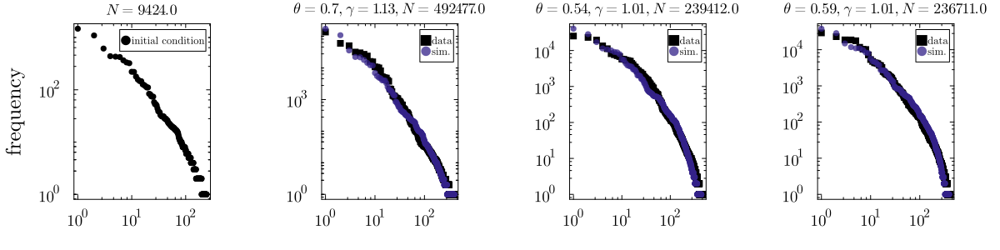

In [100]:
plot(ps1..., layout = (1,4), size = (1200,300), left_margin = 8mm, bottom_margin = 10mm, top_margin = 3mm, right_margin = 12mm)

# Index 2

Index choice below specifies the index of system we are dealing with.

In [101]:
ind_choice = 2;

In [102]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [103]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

130072.0

In [104]:
small_to_large = sortperm(sizes);

In [105]:
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [106]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

18.666176081371837

Let's import the calibration results.

In [107]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.0924504,1.00613,6.92446
2,-0.367724,1.00248,6.98948
3,-0.241099,1.02641,6.77657
4,-0.537622,1.00918,7.38806
5,-0.11696,1.01718,7.6826
6,-0.0976402,0.979541,7.364
7,-0.447773,0.981394,5.45259
8,-0.317984,1.0089,5.14969
9,0.0576005,0.984839,5.70181


Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [108]:
top10i = sortperm(sizes,rev=true)[1:10];

In [109]:
guess_sim = dsim.create_cell(calib_results[1,1],calib_results[1,2], p0_guess, convert(Int64,sizes[top10i[1]]), ic_sys, :pdf);

In [110]:
ps2 = []

Any[]

In [111]:
s1 = scatter(sort(data[small_to_large[2]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "initial condition", marker = :circle, color = :black)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N=%$(sum(ic_sys))")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, ylabel = "frequency")
push!(ps2, s1)

1-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}

In [112]:
gs2 = [dsim.create_cell(calib_results[i,1],calib_results[i,2], p0_guess, convert(Int64,sizes[top10i[i]]), ic_sys, :pdf) for i in 1:3]

3-element Vector{Vector{Float64}}:
 [5926.0, 5047.0, 4191.0, 3803.0, 3743.0, 3613.0, 3453.0, 3090.0, 2780.0, 2578.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [8317.0, 7390.0, 4094.0, 2642.0, 2237.0, 2204.0, 2069.0, 2040.0, 1621.0, 1555.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [6904.0, 6532.0, 3763.0, 3098.0, 2722.0, 2314.0, 2225.0, 2149.0, 2134.0, 2066.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [113]:
for i in 1:3
    guess_sim = gs2[i]
    s = scatter(sort(data[top10i[i]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
    scatter!(guess_sim, label = "sim.", grid = false, minorgrid = false, color = cpal_plot[2], alpha = 0.75)
    plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, 
    title = L"\theta = %$(round(calib_results[i,1], digits = 2)), \gamma = %$(round(calib_results[i,2], digits = 2)), N=%$(sum(data[top10i[i]][!,:count]))")
    plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
    push!(ps2,s)
end

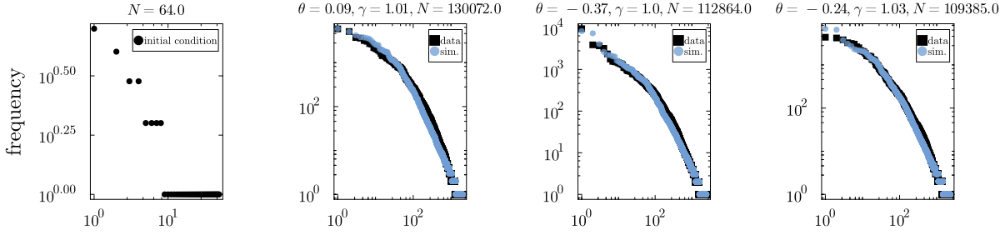

In [114]:
plot(ps2..., layout = (1,4), size = (1200,300), left_margin = 8mm, bottom_margin = 10mm, top_margin = 3mm, right_margin = 12mm)

# Index 3

Index choice below specifies the index of system we are dealing with.

In [115]:
ind_choice = 3;

In [116]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [117]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

561030.0

In [118]:
small_to_large = sortperm(sizes);

In [119]:
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [120]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

132.4444810244406

Let's import the calibration results.

In [121]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.812961,1.13346,8.45692
2,0.751581,1.11364,13.305
3,0.683318,1.09956,13.1975
4,0.720985,1.10969,11.6918
5,0.700506,1.11233,13.0983
6,0.529608,1.08131,7.61163
7,0.738486,1.12591,10.2036
8,0.792956,1.13554,7.35457
9,0.663857,1.10513,6.56366


Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [122]:
top10i = sortperm(sizes,rev=true)[1:10];

In [123]:
guess_sim = dsim.create_cell(calib_results[1,1],calib_results[1,2], p0_guess, convert(Int64,sizes[top10i[1]]), ic_sys, :pdf);

In [124]:
ps3 = []

Any[]

In [125]:
s1 = scatter(sort(data[small_to_large[2]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "initial condition", marker = :circle, color = :black)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N=%$(sum(ic_sys))")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, ylabel = "frequency")
push!(ps3, s1)

1-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}

In [126]:
gs3 = [dsim.create_cell(calib_results[i,1],calib_results[i,2], p0_guess, convert(Int64,sizes[top10i[i]]), ic_sys, :pdf) for i in 1:3]

3-element Vector{Vector{Float64}}:
 [163950.0, 114549.0, 51527.0, 28414.0, 15489.0, 14073.0, 12366.0, 6437.0, 5746.0, 4579.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [184052.0, 68303.0, 44118.0, 26597.0, 11656.0, 8580.0, 8537.0, 4339.0, 4311.0, 4291.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [63339.0, 55860.0, 19364.0, 14615.0, 13764.0, 8560.0, 7740.0, 7643.0, 6526.0, 5659.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [127]:
for i in 1:3
    guess_sim = gs3[i];
    s = scatter(sort(data[top10i[i]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
    scatter!(guess_sim, label = "sim.", grid = false, minorgrid = false, color = cpal_plot[3], alpha = 0.75)
    plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, 
    title = L"\theta = %$(round(calib_results[i,1], digits = 2)), \gamma = %$(round(calib_results[i,2], digits = 2)), N=%$(sum(data[top10i[i]][!,:count]))")
    plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
    push!(ps3,s)
end

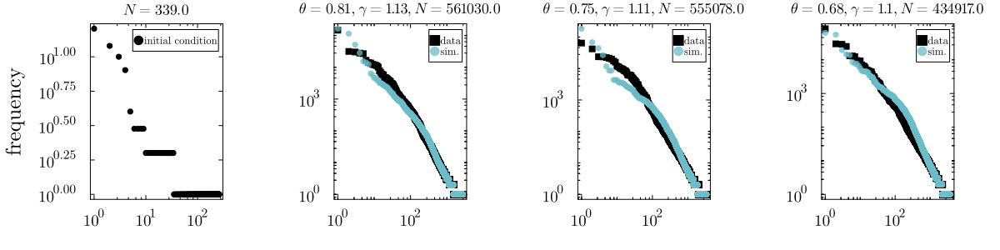

In [128]:
plot(ps3..., layout = (1,4), size = (1200,300), left_margin = 8mm, bottom_margin = 10mm, top_margin = 3mm, right_margin = 12mm)

# Index 4

Index choice below specifies the index of system we are dealing with.

In [129]:
ind_choice = 4;

In [130]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [131]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

13233.0

In [132]:
small_to_large = sortperm(sizes);

In [133]:
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [134]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

6.519519153790294

Let's import the calibration results.

In [135]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.559432,1.21983,2.32169
2,0.552976,1.18592,1.82769
3,0.420694,1.16813,1.6482
4,0.378424,1.27099,2.01928
5,0.400471,1.1879,0.925094
6,0.547882,1.25441,1.86644
7,0.808893,1.40004,1.02967
8,0.679338,1.28704,1.15671
9,1.49596,1.49396,12.5273


Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [136]:
top10i = sortperm(sizes,rev=true)[1:10];

In [137]:
guess_sim = dsim.create_cell(calib_results[1,1],calib_results[1,2], p0_guess, convert(Int64,sizes[top10i[1]]), ic_sys, :pdf);

In [138]:
ps4 = []

Any[]

In [139]:
s1 = scatter(sort(data[small_to_large[2]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "initial condition", marker = :circle, color = :black)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N=%$(sum(ic_sys))")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, ylabel = "frequency")
push!(ps4, s1)

1-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}

In [140]:
gs4 = [dsim.create_cell(calib_results[i,1],calib_results[i,2], p0_guess, convert(Int64,sizes[top10i[i]]), ic_sys, :pdf) for i in 1:3]

3-element Vector{Vector{Float64}}:
 [3953.0, 3566.0, 818.0, 518.0, 451.0, 398.0, 389.0, 317.0, 235.0, 187.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [2148.0, 1538.0, 1233.0, 533.0, 402.0, 389.0, 350.0, 311.0, 284.0, 166.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [1161.0, 993.0, 362.0, 232.0, 198.0, 191.0, 155.0, 152.0, 143.0, 128.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [141]:
for i in 1:3
    guess_sim = gs4[i];
    s = scatter(sort(data[top10i[i]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
    scatter!(guess_sim, label = "sim.", grid = false, minorgrid = false, color = cpal_plot[4], alpha = 0.75)
    plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, 
    title = L"\theta = %$(round(calib_results[i,1], digits = 2)), \gamma = %$(round(calib_results[i,2], digits = 2)), N=%$(sum(data[top10i[i]][!,:count]))")
    plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
    push!(ps4,s)
end

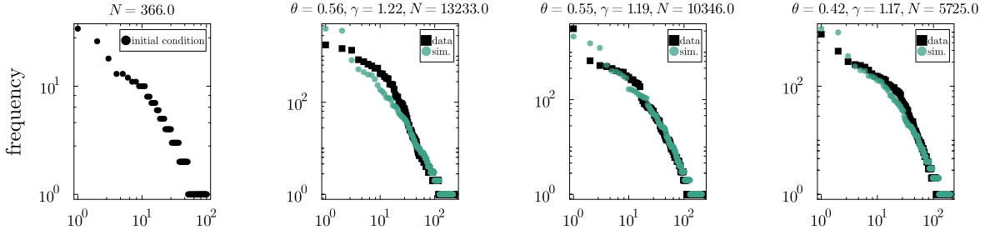

In [142]:
plot(ps4..., layout = (1,4), size = (1200,300), left_margin = 8mm, bottom_margin = 10mm, top_margin = 3mm, right_margin = 12mm)

# Index 5

Index choice below specifies the index of system we are dealing with.

In [143]:
ind_choice = 5;

In [144]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [145]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

41455.0

In [146]:
small_to_large = sortperm(sizes);

In [147]:
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [148]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

24.63634429287424

Let's import the calibration results.

In [149]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,-0.0395186,1.08115,2.25316
2,-9.16463,0.93794,14.1867
3,0.284171,1.10868,4.80346
4,-0.247142,1.06863,2.47499
5,-0.893362,1.0326,2.47345
6,-0.13654,1.06993,3.52645
7,0.305682,1.08403,2.09734
8,-2.37923,1.01823,2.07429
9,-8.9216,0.948729,8.52914


Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [150]:
top10i = sortperm(sizes,rev=true)[1:10];

In [151]:
guess_sim = dsim.create_cell(calib_results[1,1],calib_results[1,2], p0_guess, convert(Int64,sizes[top10i[1]]), ic_sys, :pdf);

In [152]:
ps5 = []

Any[]

In [153]:
s1 = scatter(sort(data[small_to_large[2]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "initial condition", marker = :circle, color = :black)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N=%$(sum(ic_sys))")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, ylabel = "frequency")
push!(ps5, s1)

1-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}

In [154]:
gs5 = [dsim.create_cell(calib_results[i,1],calib_results[i,2], p0_guess, convert(Int64,sizes[top10i[i]]), ic_sys, :pdf) for i in 1:3]

3-element Vector{Vector{Float64}}:
 [3763.0, 3511.0, 2515.0, 2335.0, 2268.0, 1832.0, 1484.0, 1362.0, 820.0, 784.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [1900.0, 1571.0, 1303.0, 1297.0, 1231.0, 1129.0, 875.0, 860.0, 686.0, 561.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [3788.0, 3330.0, 2477.0, 2423.0, 1989.0, 1857.0, 1403.0, 1366.0, 755.0, 712.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [155]:
for i in 1:3
    guess_sim = gs5[i];
    s = scatter(sort(data[top10i[i]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
    scatter!(guess_sim, label = "sim.", grid = false, minorgrid = false, color = cpal_plot[5], alpha = 0.75)
    plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, 
    title = L"\theta = %$(round(calib_results[i,1], digits = 2)), \gamma = %$(round(calib_results[i,2], digits = 2)), N=%$(sum(data[top10i[i]][!,:count]))")
    plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
    push!(ps5,s)
end

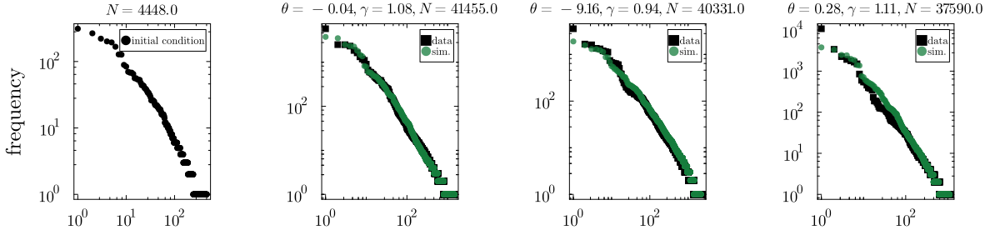

In [156]:
plot(ps5..., layout = (1,4), size = (1200,300), left_margin = 8mm, bottom_margin = 10mm, top_margin = 3mm, right_margin = 12mm)

# Index 6

Index choice below specifies the index of system we are dealing with.

In [157]:
ind_choice = 6;

In [158]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [159]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

59759.0

In [160]:
small_to_large = sortperm(sizes);

In [161]:
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [162]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

1.829608314092498

Let's import the calibration results.

In [163]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.661997,1.02037,2.93821
2,0.704764,1.00746,2.35486
3,0.645872,0.987012,1.0958
4,0.706524,0.98226,2.22814
5,0.715997,1.03381,2.98273
6,0.645311,0.996235,1.73135
7,0.579885,0.954036,2.33085
8,0.643776,1.02685,1.33038
9,0.638408,1.00744,1.97999


Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [164]:
top10i = sortperm(sizes,rev=true)[1:10];

In [165]:
guess_sim = dsim.create_cell(calib_results[1,1],calib_results[1,2], p0_guess, convert(Int64,sizes[top10i[1]]), ic_sys, :pdf);

In [166]:
ps6 = []

Any[]

In [167]:
s1 = scatter(sort(data[small_to_large[2]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "initial condition", marker = :circle, color = :black)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N=%$(sum(ic_sys))")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, ylabel = "frequency", xlabel = "rank")
push!(ps6, s1)

1-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}

In [168]:
gs6 = [dsim.create_cell(calib_results[i,1],calib_results[i,2], p0_guess, convert(Int64,sizes[top10i[i]]), ic_sys, :pdf) for i in 1:3]

3-element Vector{Vector{Float64}}:
 [12952.0, 10381.0, 10113.0, 8662.0, 3378.0, 3321.0, 2682.0, 2646.0, 1195.0, 627.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [12679.0, 9328.0, 9280.0, 7997.0, 3172.0, 3093.0, 2799.0, 2771.0, 1418.0, 575.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [10870.0, 8652.0, 8120.0, 7234.0, 3276.0, 3202.0, 2412.0, 2193.0, 1413.0, 686.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [169]:
for i in 1:3
    guess_sim = gs6[i];
    s = scatter(sort(data[top10i[i]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
    scatter!(guess_sim, label = "sim.", grid = false, minorgrid = false, color = cpal_plot[6], alpha = 0.75)
    plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, 
    title = L"\theta = %$(round(calib_results[i,1], digits = 2)), \gamma = %$(round(calib_results[i,2], digits = 2)), N=%$(sum(data[top10i[i]][!,:count]))")
    plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, xlabel = "rank")
    push!(ps6,s)
end

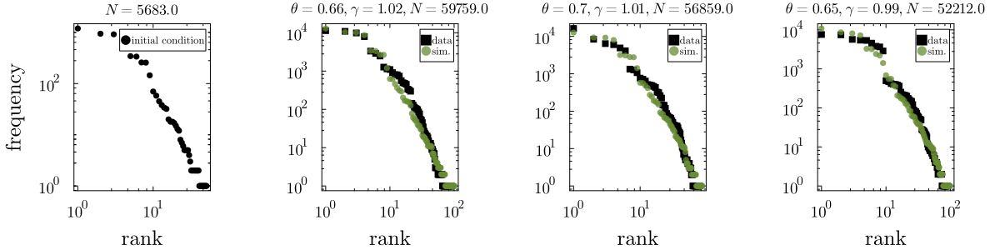

In [170]:
plot(ps6..., layout = (1,4), size = (1200,300), left_margin = 8mm, bottom_margin = 10mm, top_margin = 3mm, right_margin = 12mm)

# Index 8

Index choice below specifies the index of system we are dealing with.

In [171]:
ind_choice = 8;

In [172]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [173]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

91953.0

In [174]:
small_to_large = sortperm(sizes);

In [175]:
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [176]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

6.166505204048891

Let's import the calibration results.

In [177]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.482041,0.963974,5.91972
2,0.54143,0.99422,3.15644
3,0.540029,1.00323,2.54557
4,0.465995,1.01402,2.93203
5,0.44769,0.986365,2.10232
6,0.469691,0.976503,3.55462
7,0.434847,0.966192,2.77025
8,0.328838,0.97269,1.92308
9,0.361542,0.949238,2.89642


Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [178]:
top10i = sortperm(sizes,rev=true)[1:10];

In [179]:
guess_sim = dsim.create_cell(calib_results[1,1],calib_results[1,2], p0_guess, convert(Int64,sizes[top10i[1]]), ic_sys, :pdf);

In [180]:
ps8 = []

Any[]

In [181]:
s1 = scatter(sort(data[small_to_large[2]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "initial condition", marker = :circle, color = :black)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N=%$(sum(ic_sys))")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, ylabel = "frequency")
push!(ps8, s1)

1-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}

In [182]:
gs8 = [dsim.create_cell(calib_results[i,1],calib_results[i,2], p0_guess, convert(Int64,sizes[top10i[i]]), ic_sys, :pdf) for i in 1:3]

3-element Vector{Vector{Float64}}:
 [12232.0, 6473.0, 6448.0, 5075.0, 3528.0, 3503.0, 3473.0, 3283.0, 2821.0, 2583.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [12696.0, 5961.0, 5730.0, 4838.0, 4520.0, 3019.0, 2460.0, 2308.0, 2304.0, 2119.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [16527.0, 5990.0, 5007.0, 4390.0, 3383.0, 2950.0, 2384.0, 1765.0, 1688.0, 1620.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [183]:
for i in 1:3
    guess_sim = gs8[i];
    s = scatter(sort(data[top10i[i]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
    scatter!(guess_sim, label = "sim.", grid = false, minorgrid = false, color = cpal_plot[7], alpha = 0.75)
    plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, 
    title = L"\theta = %$(round(calib_results[i,1], digits = 2)), \gamma = %$(round(calib_results[i,2], digits = 2)), N=%$(sum(data[top10i[i]][!,:count]))")
    plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
    push!(ps8,s)
end

In [184]:
plot(ps8..., layout = (1,4), size = (1200,300), left_margin = 8mm, bottom_margin = 10mm, top_margin = 3mm, right_margin = 12mm);

# Index 9

Index choice below specifies the index of system we are dealing with.

In [185]:
ind_choice = 9;

In [186]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [187]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

616671.0

In [188]:
small_to_large = sortperm(sizes);

In [189]:
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [190]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

36.949408927933675

Let's import the calibration results.

In [191]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.589999,1.0508,3.73007
2,0.582326,1.05642,4.70687
3,0.723492,1.12957,5.05266
4,0.739314,1.12549,4.39562
5,0.739574,1.10791,3.02291
6,0.596537,1.05501,8.57043
7,0.633908,1.07903,6.00349
8,0.604236,1.05836,5.18661
9,0.530607,1.0482,3.32711


Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [192]:
top10i = sortperm(sizes,rev=true)[1:10];

In [193]:
guess_sim = dsim.create_cell(calib_results[1,1],calib_results[1,2], p0_guess, convert(Int64,sizes[top10i[1]]), ic_sys, :pdf);

In [194]:
ps9 = []

Any[]

In [195]:
s1 = scatter(sort(data[small_to_large[2]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "initial condition", marker = :circle, color = :black)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N=%$(sum(ic_sys))")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, ylabel = "frequency")
push!(ps9, s1)

1-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}

In [196]:
gs9 = [dsim.create_cell(calib_results[i,1],calib_results[i,2], p0_guess, convert(Int64,sizes[top10i[i]]), ic_sys, :pdf) for i in 1:3]

3-element Vector{Vector{Float64}}:
 [154928.0, 81928.0, 48405.0, 22300.0, 18792.0, 11622.0, 11354.0, 10773.0, 9838.0, 8935.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [145295.0, 78453.0, 44574.0, 20802.0, 18835.0, 11760.0, 11081.0, 10207.0, 8815.0, 7970.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [172335.0, 76752.0, 39803.0, 16030.0, 13617.0, 7988.0, 7606.0, 6627.0, 5954.0, 5841.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [197]:
for i in 1:3
    guess_sim = gs9[i];
    s = scatter(sort(data[top10i[i]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
    scatter!(guess_sim, label = "sim.", grid = false, minorgrid = false, color = cpal_plot[8], alpha = 0.75)
    plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, 
    title = L"\theta = %$(round(calib_results[i,1], digits = 2)), \gamma = %$(round(calib_results[i,2], digits = 2)), N=%$(sum(data[top10i[i]][!,:count]))")
    plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
    push!(ps9,s)
end

In [198]:
plot(ps9..., layout = (1,4), size = (1200,300), left_margin = 8mm, bottom_margin = 10mm, top_margin = 3mm, right_margin = 12mm);

# Index 12

Index choice below specifies the index of system we are dealing with.

In [199]:
ind_choice = 12;

In [200]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [201]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

205465.0

In [202]:
small_to_large = sortperm(sizes);

In [203]:
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [204]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

14.704079665851605

Let's import the calibration results.

In [205]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.0959447,1.07465,4.7334
2,-7.56647,0.93295,24.5357
3,0.19681,1.0512,6.54301
4,0.376414,1.07874,6.20984
5,0.434455,1.14572,6.26094
6,0.144514,1.05677,6.4174
7,0.259881,1.09473,7.08671
8,0.190514,1.00957,7.52686
9,0.341198,1.11199,6.11035


Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [206]:
top10i = sortperm(sizes,rev=true)[1:10];

In [207]:
guess_sim = dsim.create_cell(calib_results[1,1],calib_results[1,2], p0_guess, convert(Int64,sizes[top10i[1]]), ic_sys, :pdf);

In [208]:
ps12 = []

Any[]

In [209]:
s1 = scatter(sort(data[argmin(sizes)][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "initial condition", marker = :circle, color = :black)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N=%$(sum(ic_sys))")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, ylabel = "frequency")
push!(ps12, s1)

1-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}

In [210]:
gs12 = [dsim.create_cell(calib_results[i,1],calib_results[i,2], p0_guess, convert(Int64,sizes[top10i[i]]), ic_sys, :pdf) for i in 1:3]

3-element Vector{Vector{Float64}}:
 [20974.0, 17880.0, 12024.0, 10779.0, 10560.0, 8840.0, 6495.0, 5679.0, 5365.0, 5151.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [11565.0, 10087.0, 7670.0, 6930.0, 6627.0, 6175.0, 4577.0, 4302.0, 3839.0, 3769.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [12329.0, 10731.0, 7444.0, 6690.0, 6027.0, 5432.0, 4202.0, 3698.0, 3420.0, 3131.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [211]:
for i in 1:3
    guess_sim = gs12[i];
    s = scatter(sort(data[top10i[i]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
    scatter!(guess_sim, label = "sim.", grid = false, minorgrid = false, color = cpal_plot[9], alpha = 0.75)
    plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, 
    title = L"\theta = %$(round(calib_results[i,1], digits = 2)), \gamma = %$(round(calib_results[i,2], digits = 2)), N=%$(sum(data[top10i[i]][!,:count]))")
    plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
    push!(ps12,s)
end

In [212]:
plot(ps12..., layout = (1,4), size = (1200,300), left_margin = 8mm, bottom_margin = 10mm, top_margin = 3mm, right_margin = 12mm);

# Index 13

Index choice below specifies the index of system we are dealing with.

In [213]:
ind_choice = 13;

In [214]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [215]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

3324.0

In [216]:
small_to_large = sortperm(sizes);

In [217]:
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [218]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

72.2880905754131

Let's import the calibration results.

In [219]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,-9.24904,1.22877,2.71159
2,-2.0609,1.21869,1.14574
3,-9.93465,1.20581,3.7354
4,-3.28113,1.21921,0.943988
5,-7.94649,1.17448,1.08234
6,-1.42477,1.26189,0.964386
7,-9.63609,1.24506,2.38045
8,0.400026,1.2852,0.726617
9,-1.60624,1.20736,1.1988


Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [220]:
top10i = sortperm(sizes,rev=true)[1:10];

In [221]:
guess_sim = dsim.create_cell(calib_results[1,1],calib_results[1,2], p0_guess, convert(Int64,sizes[top10i[1]]), ic_sys, :pdf);

In [222]:
ps13 = []

Any[]

In [223]:
s1 = scatter(sort(data[small_to_large[2]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "initial condition", marker = :circle, color = :black)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N=%$(sum(ic_sys))")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, ylabel = "frequency")
push!(ps13, s1)

1-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}

In [224]:
gs13 = [dsim.create_cell(calib_results[i,1],calib_results[i,2], p0_guess, convert(Int64,sizes[top10i[i]]), ic_sys, :pdf) for i in 1:3]

3-element Vector{Vector{Float64}}:
 [158.0, 94.0, 68.0, 60.0, 52.0, 49.0, 46.0, 45.0, 45.0, 36.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [200.0, 181.0, 80.0, 75.0, 66.0, 61.0, 50.0, 48.0, 38.0, 38.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [155.0, 76.0, 59.0, 57.0, 50.0, 44.0, 42.0, 42.0, 30.0, 26.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [225]:
for i in 1:3
    guess_sim = gs13[i];
    s = scatter(sort(data[top10i[i]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
    scatter!(guess_sim, label = "sim.", grid = false, minorgrid = false, color = cpal_plot[10], alpha = 0.75)
    plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, 
    title = L"\theta = %$(round(calib_results[i,1], digits = 2)), \gamma = %$(round(calib_results[i,2], digits = 2)), N=%$(sum(data[top10i[i]][!,:count]))")
    plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
    push!(ps13,s)
end

In [226]:
plot(ps13..., layout = (1,4), size = (1200,300), left_margin = 8mm, bottom_margin = 10mm, top_margin = 3mm, right_margin = 12mm);

# Index 14

Index choice below specifies the index of system we are dealing with.

In [227]:
ind_choice = 14;

In [228]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [229]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

481258.0

In [230]:
small_to_large = sortperm(sizes);

In [231]:
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [232]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

99.03122020250318

Let's import the calibration results.

In [233]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.302937,1.02715,12.1845
2,0.074925,1.02336,11.0701
3,0.0014785,0.999864,14.3287
4,0.22086,1.01571,11.0865
5,0.0257418,0.988227,11.5266
6,0.116499,1.00541,9.66804
7,0.109729,1.01686,12.9755
8,0.155523,1.0088,15.2892
9,0.286567,1.02566,10.8602


Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [234]:
top10i = sortperm(sizes,rev=true)[1:10];

In [235]:
guess_sim = dsim.create_cell(calib_results[1,1],calib_results[1,2], p0_guess, convert(Int64,sizes[top10i[1]]), ic_sys, :pdf);

In [236]:
ps14 = []

Any[]

In [237]:
s1 = scatter(sort(data[small_to_large[2]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "initial condition", marker = :circle, color = :black)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"N=%$(sum(ic_sys))")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, xlabel = "rank", ylabel = "frequency")
push!(ps14, s1)

1-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}

In [238]:
gs14 = [dsim.create_cell(calib_results[i,1],calib_results[i,2], p0_guess, convert(Int64,sizes[top10i[i]]), ic_sys, :pdf) for i in 1:3]

3-element Vector{Vector{Float64}}:
 [59577.0, 28866.0, 27893.0, 25327.0, 25011.0, 10362.0, 9400.0, 8734.0, 7175.0, 7110.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [44412.0, 22989.0, 20175.0, 18329.0, 17913.0, 8272.0, 6715.0, 6659.0, 6441.0, 6339.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
 [35241.0, 18285.0, 16579.0, 15299.0, 14751.0, 7499.0, 5483.0, 5378.0, 5374.0, 5186.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [239]:
for i in 1:3
    guess_sim = gs14[i];
    s = scatter(sort(data[top10i[i]][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
    scatter!(guess_sim, label = "sim.", xlabel = "rank", grid = false, minorgrid = false, color = cpal_plot[11], alpha = 0.75)
    plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, 
    title = L"\theta = %$(round(calib_results[i,1], digits = 2)), \gamma = %$(round(calib_results[i,2], digits = 2)), N=%$(sum(data[top10i[i]][!,:count]))")
    plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
    push!(ps14,s)
end

In [240]:
plot(ps14..., layout = (1,4), size = (1200,300), left_margin = 8mm, bottom_margin = 10mm, top_margin = 3mm, right_margin = 12mm);

# All plots together

In [241]:
all_p = vcat(ps1,ps2,ps3,ps4,ps5,ps6,ps8,ps9,ps12,ps13,ps14)

44-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=1}
 ⋮
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}

In [242]:
plot(all_p..., layout = (11,4), size = (1300,3000), left_margin = 25mm, bottom_margin = 0mm, top_margin = 0mm, right_margin = 0mm);
# savefig("./calibration-plots-11x4.pdf")

In [243]:
first_6_p = vcat(ps1,ps2,ps3,ps4,ps5,ps6)
final_5_p = vcat(ps8,ps9,ps12,ps13,ps14)

20-element Vector{Any}:
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=1}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}
 Plot{Plots.GRBackend() n=2}

In [244]:
plot(first_6_p..., layout = (6,4), size = (1300,1600), left_margin = 8mm, bottom_margin = 0mm, top_margin = 0mm, right_margin = 15mm)
savefig("rf-plots-1-6.pdf")

"/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/rf-plots-1-6.pdf"

In [245]:
plot(final_5_p..., layout = (5,4), size = (1300,1300), left_margin = 8mm, bottom_margin = 0mm, top_margin = 0mm, right_margin =15mm)
savefig("rf-plots-last-5.pdf")

"/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/rf-plots-last-5.pdf"